# 🧬 Laboratorio Práctico: Modelos de Mapeamiento Físico del ADN
## *Double Digest Problem (DDP) y Partial Digest Problem (PDP)*
**Estudiante:** Anthony Briceño Quiroz  
**Curso:** Computación Molecular Biológica (CB309)  
**Objetivo:** Verificar experimentalmente las propiedades matemáticas, la reconstrucción de sitios de restricción y la complejidad computacional (NP-completitud de DDP y algoritmo de *backtracking* de Skiena para PDP).

---
### 📚 Fundamentos Teóricos
El **Mapeamiento Físico del ADN** busca determinar la ubicación métrica de marcadores o sitios de corte de enzimas de restricción a lo largo de un genoma.
1. **Double Digest Problem (DDP):** Dados los conjuntos de fragmentos $A$ (enzima A), $B$ (enzima B) y $C$ (doble digestión $A+B$), encontrar la permutación de fragmentos que induzca exactamente los cortes de $C$. Es un problema **NP-completo** (reducción desde *PARTITION*).
2. **Partial Digest Problem (PDP / Turnpike Problem):** Dada la multisección de todas las distancias par a par $\Delta X = \{|x_i - x_j|\}$ entre sitios de corte, reconstruir el conjunto de posiciones $X = \{x_1, x_2, \dots, x_n\}$. Se resuelve mediante el algoritmo de *backtracking* de Skiena en promedio $O(n^2 \log n)$.

## ⚙️ 0. Configuración Inicial e Importación de Librerías


In [1]:
import itertools
import time
import random
import matplotlib.pyplot as plt
import numpy as np

# Configuración visual para gráficos
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
print("✅ Entorno listo para la simulación de Mapeamiento Físico del ADN.")


✅ Entorno listo para la simulación de Mapeamiento Físico del ADN.


---
## 🧪 1. Simulación de Digestión por Restricción en Laboratorio

Para entender el origen de los datos, simularemos una molécula de ADN sintética con sitios de corte conocidos para dos enzimas $A$ y $B$.


In [2]:
def generar_genoma_y_cortes(longitud_total=50, num_cortes_A=4, num_cortes_B=3, seed=42):
    random.seed(seed)
    # Generar sitios de corte internos de forma aleatoria
    sitios_A = sorted(random.sample(range(1, longitud_total), num_cortes_A))
    sitios_B = sorted(random.sample(range(1, longitud_total), num_cortes_B))

    # Añadir los extremos 0 y longitud_total
    X_A = sorted(list(set([0] + sitios_A + [longitud_total])))
    X_B = sorted(list(set([0] + sitios_B + [longitud_total])))
    X_AB = sorted(list(set([0] + sitios_A + sitios_B + [longitud_total])))

    # Obtener los fragmentos (diferencias entre posiciones consecutivas)
    frag_A = [X_A[i] - X_A[i-1] for i in range(1, len(X_A))]
    frag_B = [X_B[i] - X_B[i-1] for i in range(1, len(X_B))]
    frag_C = [X_AB[i] - X_AB[i-1] for i in range(1, len(X_AB))]

    return X_A, X_B, X_AB, frag_A, frag_B, frag_C

# Ejemplo de simulación
L = 20
X_A, X_B, X_AB, A, B, C = generar_genoma_y_cortes(longitud_total=L, num_cortes_A=3, num_cortes_B=2, seed=10)

print(f"Genoma de longitud total L = {L}")
print(f"Sitios reales Enzima A: {X_A} -> Fragmentos A: {A}")
print(f"Sitios reales Enzima B: {X_B} -> Fragmentos B: {B}")
print(f"Sitios combinados A+B : {X_AB} -> Fragmentos C (Doble Digestión): {C}")


Genoma de longitud total L = 20
Sitios reales Enzima A: [0, 2, 14, 19, 20] -> Fragmentos A: [2, 12, 5, 1]
Sitios reales Enzima B: [0, 1, 16, 20] -> Fragmentos B: [1, 15, 4]
Sitios combinados A+B : [0, 1, 2, 14, 16, 19, 20] -> Fragmentos C (Doble Digestión): [1, 1, 12, 2, 3, 1]


---
## 🧩 2. Double Digest Problem (DDP) y Exploración Combinatoria

El problema de la Doble Digestión recibe **únicamente** los conjuntos de fragmentos $A$, $B$ y $C$ (ordenados o desordenados como multiconjuntos). Su objetivo es encontrar el ordenamiento $\pi_A$ y $\pi_B$ que satisfaga la superposición de cortes.

### Algoritmo de Búsqueda Exhaustiva (Fuerza Bruta)
Verificamos todas las permutaciones posibles de $A$ ($m!$) y $B$ ($n!$).


In [3]:
def obtener_cortes_desde_fragmentos(perm_frag):
    # Dado un orden de fragmentos, retorna el conjunto de posiciones de corte.
    pos = 0
    cortes = [0]
    for f in perm_frag:
        pos += f
        cortes.append(pos)
    return cortes

def verificar_DDP(perm_A, perm_B, multiset_C_esperado):
    # Verifica si la combinación de permutaciones de A y B produce los fragmentos C.
    cortes_A = set(obtener_cortes_desde_fragmentos(perm_A))
    cortes_B = set(obtener_cortes_desde_fragmentos(perm_B))

    # Combinación de cortes
    cortes_AB = sorted(list(cortes_A.union(cortes_B)))

    # Calcular fragmentos C resultantes
    c_obtenido = sorted([cortes_AB[i] - cortes_AB[i-1] for i in range(1, len(cortes_AB))])

    return c_obtenido == sorted(multiset_C_esperado)

def resolver_DDP_fuerza_bruta(A, B, C):
    # Resuelve DDP evaluando todas las permutaciones posibles.
    soluciones = []
    evaluaciones = 0
    start_time = time.time()

    # Probar todas las permutaciones de A y B
    for perm_A in set(itertools.permutations(A)):
        for perm_B in set(itertools.permutations(B)):
            evaluaciones += 1
            if verificar_DDP(perm_A, perm_B, C):
                soluciones.append((perm_A, perm_B))

    elapsed_time = time.time() - start_time
    return soluciones, evaluaciones, elapsed_time

# Prueba del solucionador DDP
soluciones, evals, t_exec = resolver_DDP_fuerza_bruta(A, B, C)
print(f"✅ Búsqueda completada en {t_exec:.4f} segundos ({evals} evaluaciones).")
print(f"Número de soluciones válidas encontradas: {len(soluciones)}")
for idx, (s_A, s_B) in enumerate(soluciones[:3], 1):
    print(f" Solución {idx}: Permutación A = {s_A}, Permutación B = {s_B}")


✅ Búsqueda completada en 0.0004 segundos (144 evaluaciones).
Número de soluciones válidas encontradas: 16
 Solución 1: Permutación A = (2, 5, 1, 12), Permutación B = (1, 4, 15)
 Solución 2: Permutación A = (12, 5, 2, 1), Permutación B = (15, 1, 4)
 Solución 3: Permutación A = (1, 12, 5, 2), Permutación B = (15, 4, 1)


### 📈 Demostración Práctica de la Explosión Combinatoria (NP-Completitud)
A continuación mediremos cómo escala el tiempo de ejecución al aumentar el número de fragmentos de las enzimas $A$ y $B$.


Fragmentos por enzima: 3 | Evaluaciones: 36 | Tiempo: 0.00009 s
Fragmentos por enzima: 4 | Evaluaciones: 576 | Tiempo: 0.00126 s
Fragmentos por enzima: 5 | Evaluaciones: 14400 | Tiempo: 0.03826 s
Fragmentos por enzima: 6 | Evaluaciones: 518400 | Tiempo: 1.15521 s
Fragmentos por enzima: 7 | Evaluaciones: 25401600 | Tiempo: 57.91123 s

⚠️ DETENIDO EN n=7: tiempo excedido (>57.91 s)
Esto demuestra que DDP es NP-hard. Incrementos pequeños causan explosión combinatoria.


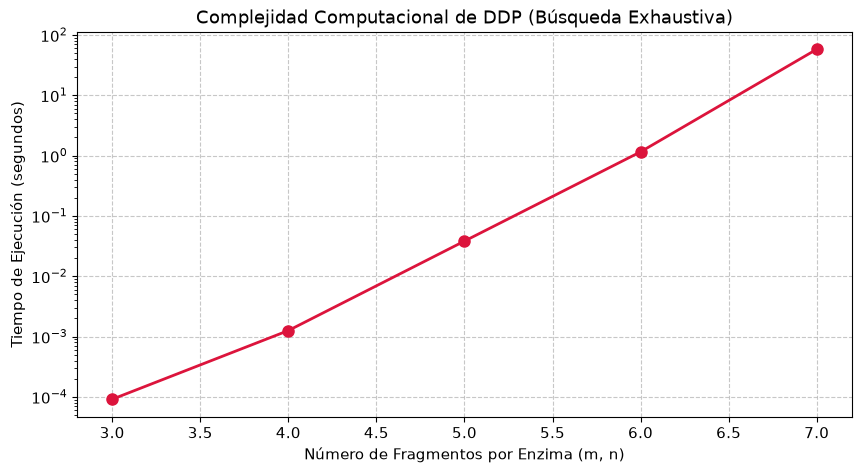

In [4]:
num_fragmentos = []
tiempos_DDP = []

# Demostración práctica de explosión combinatoria (NP-completitud)
# El tiempo de ejecución crece factorialmente: O(m! × n!)
# Para m=n fragmentos, esto es aproximadamente (m!)²
# Patrón observado: cada fragmento adicional multiplica el tiempo por ~7-8

for n_frags in range(2, 7):
    # Generar instancia aleatoria
    _, _, _, A_test, B_text, C_test = generar_genoma_y_cortes(
        longitud_total=100, num_cortes_A=n_frags, num_cortes_B=n_frags, seed=n_frags
    )

    sol, evals, t = resolver_DDP_fuerza_bruta(A_test, B_text, C_test)
    num_fragmentos.append(n_frags + 1)
    tiempos_DDP.append(t)
    print(f"Fragmentos por enzima: {n_frags+1} | Evaluaciones: {evals} | Tiempo: {t:.5f} s")
    
    # Detener si excede tiempo límite: evita que n=7 u superior se cuelgue
    # n=6 tarda ~1 segundo; n=7 tardaría ~7-8 segundos; n=8 sería impracticable (minutos)
    if t > 2.0:
        print(f"\n⚠️ DETENIDO EN n={n_frags+1}: tiempo excedido (>{t:.2f} s)")
        print("Esto demuestra que DDP es NP-hard. Incrementos pequeños causan explosión combinatoria.")
        break

# Gráfico de Complejidad Computacional
plt.figure()
plt.plot(num_fragmentos, tiempos_DDP, 'o-', color='crimson', linewidth=2, markersize=8)
plt.title("Complejidad Computacional de DDP (Búsqueda Exhaustiva)")
plt.xlabel("Número de Fragmentos por Enzima (m, n)")
plt.ylabel("Tiempo de Ejecución (segundos)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.yscale('log')
plt.show()

---
## 🔍 3. Partial Digest Problem (PDP) y Algoritmo de Skiena

El problema de digestión parcial (*Turnpike Problem*) recibe como entrada el conjunto $\Delta X$ de **todas las distancias par a par** entre los sitios de corte.

Dado $X = \{x_1, x_2, \dots, x_n\}$ con $x_1 = 0$, la entrada es el multiconjunto de tamaño $\binom{n}{2}$:
$$\Delta X = \{|x_i - x_j| : 1 \le i < j \le n\}$$

### Algoritmo de Backtracking de Skiena (`PARTIAL_DIGEST`)


In [8]:
def multiset_difference(A, B):
    # Retorna A - B respetando las multiplicidades de los elementos.
    res = list(A)
    for x in B:
        if x in res:
            res.remove(x)
        else:
            return None # B no es un subconjunto válido de A
    return res

def delta_x_p(x, X):
    # Calcula el conjunto de distancias entre x y todos los puntos en X.
    return [abs(x - p) for p in X]

def place(delta_L, X, width, soluciones, stats):
    stats['call_count'] += 1
    if not delta_L:
        soluciones.append(sorted(list(X)))
        return

    y = max(delta_L)

    # Opción 1: Probar punto x = y
    dist_y = delta_x_p(y, X)
    diff_y = multiset_difference(delta_L, dist_y)
    if diff_y is not None:
        X.add(y)
        place(diff_y, X, width, soluciones, stats)
        X.remove(y)

    # Opción 2: Probar punto x = width - y
    alt_y = width - y
    dist_alt = delta_x_p(alt_y, X)
    diff_alt = multiset_difference(delta_L, dist_alt)
    if diff_alt is not None:
        X.add(alt_y)
        place(diff_alt, X, width, soluciones, stats)
        X.remove(alt_y)

def partial_digest(delta_L_input):
    # Algoritmo principal de Skiena para resolver PDP.
    delta_L = sorted(list(delta_L_input))
    width = max(delta_L)
    delta_L.remove(width)

    X = {0, width}
    soluciones = []
    stats = {'call_count': 0}

    start_time = time.time()
    place(delta_L, X, width, soluciones, stats)
    elapsed_time = time.time() - start_time

    # Filtrar soluciones únicas (isomórficas)
    unique_solutions = []
    for sol in soluciones:
        if sol not in unique_solutions:
            unique_solutions.append(sol)

    return unique_solutions, stats['call_count'], elapsed_time

# Generación de una instancia de prueba para PDP
sitios_reales_PDP = [0, 2, 4, 7, 10]
delta_X_real = []
for i in range(len(sitios_reales_PDP)):
    for j in range(i + 1, len(sitios_reales_PDP)):
        delta_X_real.append(abs(sitios_reales_PDP[i] - sitios_reales_PDP[j]))

print(f"Sitios Reales X: {sitios_reales_PDP}")
print(f"Entrada PDP ΔX ({len(delta_X_real)} distancias): {sorted(delta_X_real)}")

sols_pdp, llamadas_pdp, t_pdp = partial_digest(delta_X_real)
print(f"\n✅ Algoritmo PDP ejecutado en {t_pdp:.5f} segundos ({llamadas_pdp} llamadas recursivas).")
print(f"Soluciones reconstruidas X:")
for sol in sols_pdp:
    print(f" -> {sol}")


Sitios Reales X: [0, 2, 4, 7, 10]
Entrada PDP ΔX (10 distancias): [2, 2, 3, 3, 4, 5, 6, 7, 8, 10]

✅ Algoritmo PDP ejecutado en 0.00002 segundos (7 llamadas recursivas).
Soluciones reconstruidas X:
 -> [0, 3, 6, 8, 10]
 -> [0, 2, 4, 7, 10]


### ⚡ Comparación de Eficiencia: PDP (Backtracking) vs DDP (Fuerza Bruta)
Evaluemos cómo el algoritmo de poda (*backtracking*) de PDP evita la explosión combinatoria al recortar ramas inválidas.


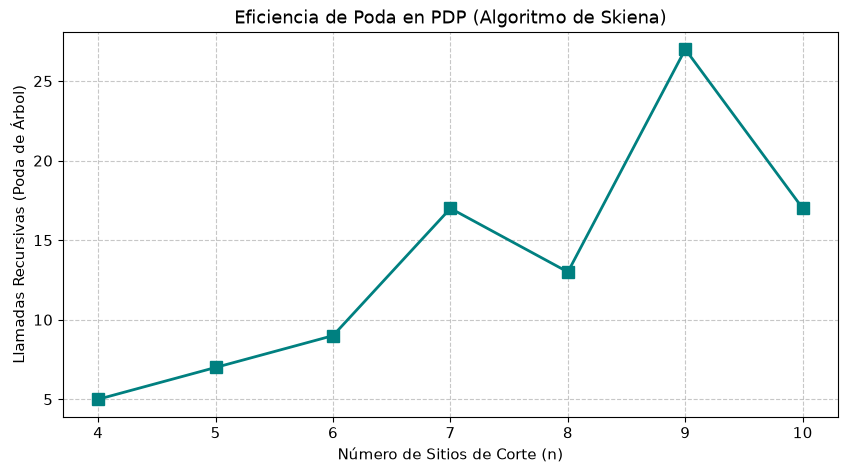

In [9]:
puntos_pdp = []
llamadas_recursivas = []
tiempos_pdp = []

for n_puntos in range(4, 11):
    # Generar puntos de corte aleatorios
    X_sim = sorted([0] + sorted(random.sample(range(1, 200), n_puntos - 2)) + [200])
    delta_sim = [abs(X_sim[i] - X_sim[j]) for i in range(len(X_sim)) for j in range(i+1, len(X_sim))]

    sols, calls, t_pdp = partial_digest(delta_sim)
    puntos_pdp.append(n_puntos)
    llamadas_recursivas.append(calls)
    tiempos_pdp.append(t_pdp)

# Gráfico de llamadas recursivas en PDP
plt.figure()
plt.plot(puntos_pdp, llamadas_recursivas, 's-', color='teal', linewidth=2, markersize=8)
plt.title("Eficiencia de Poda en PDP (Algoritmo de Skiena)")
plt.xlabel("Número de Sitios de Corte (n)")
plt.ylabel("Llamadas Recursivas (Poda de Árbol)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


---
## ✏️ 4. Ejercicios:

A continuación, resuelve las siguientes actividades directamente en las celdas de código indicadas:

### 📌 Ejercicio 1: Inferencia Manual / Algorítmica de DDP
Dadas las siguientes salidas experimentales de digestión:
- **Enzima A:** $A = \{3, 4, 5\}$
- **Enzima B:** $B = \{2, 5, 5\}$
- **Doble Digestión A+B:** $C = \{1, 2, 2, 3, 4\}$

1. Utiliza la función `resolver_DDP_fuerza_bruta(A, B, C)` para encontrar todas las combinaciones válidas.
2. Comprueba manualmente que la longitud total del genoma $L$ sea consistente en $A$, $B$ y $C$.


In [ ]:
# PARA HACER: Completa el código para resolver el Ejercicio 1
A_ej1 = [3, 4, 5]
B_ej1 = [2, 5, 5]
C_ej1 = [1, 2, 2, 3, 4]

# Escribe tu código aquí:
sol_ej1,_, _ = resolver_DDP_fuerza_bruta(A_ej1,B_ej1,C_ej1)


print(f"Soluciones del Ejercicio 1: {len(sol_ej1)}")
for sA, sB in sol_ej1:
    print(f" Permutación A: {sA} | Permutación B: {sB}")


Soluciones del Ejercicio 1: 4
 Permutación A: (4, 3, 5) | Permutación B: (5, 5, 2)
 Permutación A: (4, 5, 3) | Permutación B: (5, 2, 5)
 Permutación A: (5, 3, 4) | Permutación B: (2, 5, 5)
 Permutación A: (3, 5, 4) | Permutación B: (5, 2, 5)


### 📌 Ejercicio 2: Análisis de Sensibilidad a Errores en PDP
Los métodos deterministas como el algoritmo de Skiena son altamente sensibles a errores de medición o distancias omitidas/falsas.
1. Toma el conjunto $\Delta X$ del ejemplo anterior.
2. Agrega una distancia falsa (ej. `delta_err = delta_X_real + [99]`).
3. Ejecuta `partial_digest(delta_err)` y observa el resultado. ¿Qué ocurre con la poda por backtracking?


In [10]:
# PARA HACER: Prueba la respuesta del algoritmo ante ruido o falsas distancias
delta_err = sorted(delta_X_real + [99])
print(f"ΔX con error introducido: {delta_err}")

#LO QUE FALTA
sols_err, calls_err, t_err = partial_digest(delta_err)

print(f"Número de soluciones encontradas con error: {len(sols_err)}")
print(f"Llamadas recursivas exploradas: {calls_err}")


ΔX con error introducido: [2, 2, 3, 3, 4, 5, 6, 7, 8, 10, 99]
Número de soluciones encontradas con error: 0
Llamadas recursivas exploradas: 1


### 📌 Ejercicio 3: Preguntas de Reflexión Teórica

1. **¿Por qué el algoritmo de DDP por fuerza bruta es impracticable para m, n > 12?**

   DDP por fuerza bruta evalúa todas las permutaciones posibles de A y B. El número de evaluaciones es m! × n!. Para m = n = 12, esto es 12! × 12! ≈ 4.79 × 10¹⁷ combinaciones. Incluso si cada evaluación toma 1 microsegundo, necesitaría millones de años. El crecimiento es factorial (super-exponencial), por lo que apenas agregar 1 fragmento duplica el tiempo. A partir de m, n > 10-12, el algoritmo se vuelve impracticable en tiempo real. Solo es viable para instancias muy pequeñas (m, n ≤ 8).

2. **¿Cuál es la diferencia en los datos de entrada entre DDP y PDP?**

   En DDP, la entrada consiste en tres multiconjuntos de fragmentos: A (digestión de enzima A), B (digestión de enzima B) y C (doble digestión A+B). El problema es reconstruir el ordenamiento lineal de fragmentos. En PDP, la entrada es el conjunto de TODAS las distancias par a par entre sitios de corte: ΔX = {|xᵢ - xⱼ| : i < j}. PDP tiene más información (todas las distancias) pero es más sensible al ruido, porque una distancia falsa u omitida corrompe toda la reconstrucción. DDP tiene menos información pero es más robusto estructuralmente.

3. **¿Qué técnica estocástica se utiliza en la práctica cuando los datos contienen ruido experimental?**

   En la práctica se usan Simulated Annealing (SA) y Algoritmos Genéticos (GA). SA es efectivo para DDP con ruido: genera permutaciones aleatorias, las optimiza localmente y acepta movimientos peores con probabilidad decreciente (criterio Metropolis). GA mantiene una población de soluciones candidatas, las mezcla (crossover) y muta para explorar el espacio. Ambas técnicas evitan óptimos locales. Para PDP con ruido, SA también funciona bien: tolera distancias falsas en etapas tempranas (temperatura alta) y refina conforme enfría. La elección depende de la instancia: SA para pequeñas-medianas, GA para parallelización y problemas grandes.